In [1]:
# import os
# os.environ['JAX_PLATFORMS'] = 'cpu'

import os
os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'

# This is required to run multiple processes with JAX.
from multiprocessing import set_start_method
set_start_method('forkserver', force=True)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
from tqdm import tqdm
from pathlib import Path

print(jax.devices())
# jax.config.update("jax_debug_nans", True)

from config import Config
import data

[CudaDevice(id=0)]


In [3]:
cfg = Config.from_file("/nas/cee-water/cjgleason/ted/swot-ml/runs/test/swot_vD.yml")
cfg.quiet = False

In [4]:
train_dataset = data.MCFLIDataset(cfg, 'train')
train_loader = data.MCFLIDataLoader(cfg, train_dataset)

Caches will be stored at: /scratch4/workspace/tlanghorst_umass_edu-zbs_vD/_cache4/8fba0b5cd6b6f05c
Indices for train already exist. Skipping.
Calculating training statistics for encoding and normalization...
Loading basin graphs...Done!
Loading optimized indices for train...Done!


Caching basins in memory:  26%|██▌       | 377/1454 [02:04<03:43,  4.82it/s]

BRANA-57250000 not found in cache


Caching basins in memory:  27%|██▋       | 386/1454 [02:07<04:33,  3.91it/s]

BRANA-59100000 not found in cache


Caching basins in memory:  28%|██▊       | 401/1454 [02:16<07:04,  2.48it/s]

BRANA-65240000 not found in cache


Caching basins in memory:  30%|██▉       | 431/1454 [02:29<08:33,  1.99it/s]

BRANA-84853000 not found in cache


Caching basins in memory: 100%|██████████| 1454/1454 [06:50<00:00,  3.54it/s]


In [30]:
test_dataset = data.MCFLIDataset(cfg, 'test')
test_loader = data.MCFLIDataLoader(cfg, test_dataset)

Caches will be stored at: /scratch4/workspace/tlanghorst_umass_edu-zbs_vD/_cache4/8fba0b5cd6b6f05c
Indices for test already exist. Skipping.
Calculating training statistics for encoding and normalization...
Loading basin graphs...Done!
Loading optimized indices for test...Done!


Caching basins in memory: 100%|██████████| 278/278 [03:24<00:00,  1.36it/s]


In [104]:
import equinox as eqx

class ReachParameterNet(eqx.Module):
    A0_net: eqx.nn.MLP
    n_net: eqx.nn.MLP
    def __init__(self, in_size, hidden_size, depth, *, key):
        k1, k2 = jax.random.split(key)
        # Separate heads to eliminate parameter interference
        self.A0_net = eqx.nn.MLP(
            in_size=in_size,
            out_size=1,
            width_size=hidden_size,
            depth=depth,
            key=k1
        )
        self.n_net = eqx.nn.MLP(
            in_size=in_size,
            out_size=1,
            width_size=hidden_size,
            depth=depth,
            key=k2
        )
    
    def __call__(self, x_d, d_mask, x_s, hws):
        def get_params(x_temporal):
            feat = jnp.concat([x_temporal, x_s])
            return jnp.concat([self.A0_net(feat), self.n_net(feat)])
        embeddings = jax.vmap(get_params)(x_d)
        params = jnp.mean(embeddings, axis=0, where=d_mask[:, None])
        
        dh = hws[:, 0]
        w = hws[:, 1]
        s = hws[:, 2]
        dA = w * dh
        
        # A0 scaled by mean width to provide physical context
        avg_w = jnp.mean(w, where=d_mask)
        A0_depth = jax.nn.softplus(params[0]) 
        A0 = (A0_depth * avg_w) - jnp.min(dA) + 1e-6
        A = A0 + dA
        
        # soft, symmetric mapping of latent states 
        n_center = 0.3  
        n_half_range = 0.299
        n = n_center + n_half_range * jnp.tanh(params[1])
        Q = (1/n) * jnp.power(A, 5/3) * jnp.power(w, -2/3) * jnp.sqrt(s)
        
        return Q, A0, n


def log_mse_loss(model, x_d, d_mask, x_s, hws, y, norm_fn):
    y_hat, _, _ = jax.vmap(model)(x_d, d_mask, x_s, hws)
    err = norm_fn(y_hat) - y
    return jnp.nanmean(jnp.nanmean(err**2, axis=1, where=d_mask))

def log_mae_loss(model, x_d, d_mask, x_s, hws, y, norm_fn):
    y_hat, _, _ = jax.vmap(model)(x_d, d_mask, x_s, hws)
    err = norm_fn(y_hat) - y
    return jnp.nanmean(jnp.nanmean(jnp.abs(err), axis=1, where=d_mask))

def nse_loss(model, x_d, d_mask, x_s, hws, y, denorm_fn):
    y_hat, _, _ = jax.vmap(model)(x_d, d_mask, x_s, hws)
    y_obs = target_denorm_fn(y)
    
    sq_error = jnp.abs(y_obs - y_hat)
    numer = jnp.sum(sq_error, axis=1, where=d_mask)
    
    y_obs_mean = jnp.mean(y_obs, axis=1, where=d_mask)
    sq_dev = jnp.abs((y_obs - y_obs_mean[:,jnp.newaxis]))
    denom = jnp.sum(sq_dev, axis=1, where=d_mask) + 0.1

    return jnp.mean(numer / denom)





In [128]:
import equinox as eqx
import jax
import jax.numpy as jnp
from jax.scipy.special import logsumexp

class MixtureHead(eqx.Module):
    net: eqx.nn.MLP
    n_components: int

    def __init__(self, in_size, hidden_size, depth, n_components, *, key):
        self.n_components = n_components
        # Outputs: n_components * (weight_logit, mean, log_std)
        self.net = eqx.nn.MLP(
            in_size=in_size,
            out_size=n_components * 3,
            width_size=hidden_size,
            depth=depth,
            key=key
        )

    def __call__(self, x):
        out = self.net(x)
        logits, means, log_stds = jnp.split(out, 3, axis=-1)
        log_weights = jax.nn.log_softmax(logits, axis=-1)   # (K,)
        log_stds = jnp.clip(log_stds, -6, 0)               # numerical stability
        return log_weights, means, log_stds

    def sample(self, x, key):
        log_weights, means, log_stds = self(x)
        k1, k2 = jax.random.split(key)
        # Gumbel-max trick to sample component
        component = jnp.argmax(
            log_weights + jax.random.gumbel(k1, shape=log_weights.shape)
        )
        mean = means[component]
        std = jnp.exp(log_stds[component])
        return mean + std * jax.random.normal(k2, shape=mean.shape)

    def mean(self, x):
        """E[x] = sum_k w_k * mu_k"""
        log_weights, means, _ = self(x)
        return jnp.sum(jnp.exp(log_weights) * means)

    def log_prob(self, x, value):
        """Log likelihood of a scalar value under the mixture."""
        log_weights, means, log_stds = self(x)
        stds = jnp.exp(log_stds)
        log_component_probs = (
            -0.5 * ((value - means) / stds) ** 2
            - log_stds
            - 0.5 * jnp.log(2 * jnp.pi)
        )
        return logsumexp(log_weights + log_component_probs)

        
        
class ReachParameterNet(eqx.Module):
    A0_head: MixtureHead
    n_head: MixtureHead
    n_components: int
    n_samples: int

    def __init__(self, in_size, hidden_size, depth, n_components=4, n_samples=32, *, key):
        k1, k2 = jax.random.split(key)
        self.n_components = n_components
        self.n_samples = n_samples
        self.A0_head = MixtureHead(in_size, hidden_size, depth, n_components, key=k1)
        self.n_head  = MixtureHead(in_size, hidden_size, depth, n_components, key=k2)

    def __call__(self, x_d, d_mask, x_s, hws, key):
        def get_gmm_params(x_temporal):
            feat = jnp.concat([x_temporal, x_s])
            return self.A0_head(feat), self.n_head(feat)
    
        all_A0_gmm, all_n_gmm = jax.vmap(get_gmm_params)(x_d)
    
        k1, k2 = jax.random.split(key)
        A0_samples = self._sample_gmm_all(all_A0_gmm, k1)  # (T, S)
        n_samples  = self._sample_gmm_all(all_n_gmm,  k2)  # (T, S)
    
        # Guard: if ALL timesteps masked, mean is undefined — default to 0
        n_valid = jnp.sum(d_mask)
        mask = d_mask[:, None]
    
        A0_latent = jnp.where(n_valid > 0,
                        jnp.sum(A0_samples * mask, axis=0) / jnp.maximum(n_valid, 1),
                        jnp.zeros(self.n_samples))
        n_latent  = jnp.where(n_valid > 0,
                        jnp.sum(n_samples  * mask, axis=0) / jnp.maximum(n_valid, 1),
                        jnp.zeros(self.n_samples))
    
        dh, w, s = hws[:, 0], hws[:, 1], hws[:, 2]
        dA    = w * dh
        avg_w = jnp.sum(w * d_mask) / jnp.maximum(n_valid, 1)  # safe masked mean
        min_dA = jnp.min(dA)  # can be -inf if dA has bad values — guard it:
        min_dA = jnp.where(jnp.isfinite(min_dA), min_dA, 0.0)
    
        def manning(a0_lat, n_lat):
            # Clamp before any nonlinear transform
            a0_lat = jnp.clip(a0_lat, -5.0, 5.0)
            n_lat  = jnp.clip(n_lat,  -5.0, 5.0)
            A0 = (jax.nn.softplus(a0_lat) * avg_w) - min_dA + 1e-6
            A  = A0 + dA
            # Guard negative areas before fractional power
            A  = jnp.clip(A, 1e-6, None)
            n  = 0.3 + 0.299 * jnp.tanh(n_lat)
            Q  = (1/n) * jnp.power(A, 5/3) * jnp.power(w, -2/3) * jnp.sqrt(s)
            # Final guard — don't let Q explode into the loss
            Q  = jnp.clip(Q, 0.0, 1e8)
            return Q, A0, n
    
        Q_samples, A0_out, n_out = jax.vmap(manning)(A0_latent, n_latent)
        return Q_samples, A0_out, n_out


    def _sample_gmm_all(self, gmm_params, key):
        """Sample S values from each of T GMMs. Returns (T, S)."""
        log_weights, means, log_stds = gmm_params  # each (T, K)
        T = means.shape[0]
        keys = jax.random.split(key, T)

        def sample_one(lw, mu, ls, k):
            # Draw S samples from a single K-component GMM
            k1, k2 = jax.random.split(k)
            # (S,) component indices via Gumbel-max
            gumbels = jax.random.gumbel(k1, shape=(self.n_samples, self.n_components))
            components = jnp.argmax(lw[None, :] + gumbels, axis=-1)  # (S,)
            # Gather means and stds for selected components
            sel_mu  = mu[components]               # (S,)
            sel_std = jnp.exp(ls[components])      # (S,)
            samples = sel_mu + sel_std * jax.random.normal(k2, shape=(self.n_samples,))
            # Clamp latent samples to a sane range before physics transforms
            return jnp.clip(samples, -5.0, 5.0)

        return jax.vmap(sample_one)(log_weights, means, log_stds, keys)  # (T, S)


def probabilistic_loss(model, x_d, d_mask, x_s, hws, y, norm_fn, key):
    keys = jax.random.split(key, x_d.shape[0])
    Q_samples, _, _ = jax.vmap(model)(x_d, d_mask, x_s, hws, keys)
    # Q_samples: (B, S, num_reaches)

    y_hat = jax.vmap(jax.vmap(norm_fn))(Q_samples)  # (B, S, num_reaches)

    mu_q  = jnp.mean(y_hat, axis=1)           # (B, num_reaches)
    var_q = jnp.mean((y_hat - mu_q[:, None, :]) ** 2, axis=1)
    std_q = jnp.sqrt(var_q + 1e-6)            # fused for numerical stability

    err = (y - mu_q) / std_q
    nll = jnp.log(std_q) + 0.5 * err**2

    valid = d_mask & jnp.isfinite(nll)
    return jnp.sum(jnp.where(valid, nll, 0.0)) / jnp.maximum(jnp.sum(valid), 1)

In [10]:
key = jax.random.PRNGKey(0)
model = ReachParameterNet(in_size, 64, 4, key=key)

out = jax.vmap(model)(x_d, d_mask, x_s, hws)#[...,0].shape

NameError: name 'x_d' is not defined

In [9]:
sample = train_dataset[0]
d_size = sample['x_d'].shape[-1]
s_size = sample['x_s'].shape[-1]

in_size = d_size + s_size
out_size = 1

In [20]:
x_d.shape

(256, 200, 18)

In [15]:
for batch in train_loader:
    basin, subbasin, x_d, d_mask, x_s, hws, y = batch
    d_mask = d_mask[..., 0] #bandaid
    y = y[...,0]
    break

key = jax.random.PRNGKey(0)
tmp_model = ReachParameterNet(in_size, 64, 4, key=key)

batch_keys = jax.random.split(key, 256)
y_hat, A0, n = jax.vmap(tmp_model)(x_d, d_mask, x_s, hws, key=batch_keys)

In [19]:
n.shape

(256, 32)

In [129]:
import optax
from functools import partial

jax.config.update("jax_debug_nans", True)

keys = jax.random.split(jax.random.PRNGKey(0))
# model = ReachParameterNet(in_size, 64, 4, key=key)
model = ReachParameterNet(in_size, 256, 4, key=keys[0])

optim = optax.adamw(learning_rate=0.0001, weight_decay=0.1)
trainable_model = eqx.filter(model, eqx.is_array)
opt_state = optim.init(trainable_model)


@eqx.filter_jit
def make_step(model, x_d, d_mask, x_s, hws, y, norm_fn, denorm_fn, opt_state, key):
    # loss, grads = eqx.filter_value_and_grad(log_mse_loss)(model, x_d, d_mask, x_s, hws, y, norm_fn)
    # loss, grads = eqx.filter_value_and_grad(log_mae_loss)(model, x_d, d_mask, x_s, hws, y, norm_fn)
    # loss, grads = eqx.filter_value_and_grad(nse_loss)(model, x_d, d_mask, x_s, hws, y, denorm_fn)
    loss, grads = eqx.filter_value_and_grad(probabilistic_loss)(model, x_d, d_mask, x_s, hws, y, norm_fn, key)
    updates, opt_state = optim.update(grads, opt_state, params=model)
    model = eqx.apply_updates(model, updates)
    return loss, model, opt_state


train_losses = []
test_losses = []
target_norm_fn = partial(train_dataset.normalize, name='discharge')
target_denorm_fn = partial(train_dataset.denormalize, name='discharge')

epoch_iter = tqdm(range(100), desc='Epoch:')
for epoch in epoch_iter:
    e_losses = []
    for batch in train_loader:
        basin, subbasin, x_d, d_mask, x_s, hws, y = batch
        d_mask = d_mask[..., 0] #bandaid
        y = y[...,0]
        step_key = keys[1]
        keys = jax.random.split(keys[0])

        loss, model, opt_state = make_step(model, x_d, d_mask, x_s, hws, y, target_norm_fn, target_denorm_fn, opt_state, step_key)
        e_losses.append(loss.item())
        
    train_losses.append(np.mean(e_losses))


    e_losses = []
    for batch in test_loader:
        basin, subbasin, x_d, d_mask, x_s, hws, y = batch
        d_mask = d_mask[..., 0] #bandaid
        y = y[...,0]

        # loss = eqx.filter_jit(log_mse_loss)(model, x_d, d_mask, x_s, hws, y, target_norm_fn)
        # loss = eqx.filter_jit(nse_loss)(model, x_d, d_mask, x_s, hws, y, target_denorm_fn)
        loss = eqx.filter_jit(probabilistic_loss)(model, x_d, d_mask, x_s, hws, y, target_norm_fn, step_key)
        e_losses.append(loss.item())
        
    test_losses.append(np.mean(e_losses))
    

    epoch_iter.set_postfix_str(f"train: {train_losses[-1]:0.4f}, test: {test_losses[-1]:0.4f}")


Epoch:: 100%|██████████| 100/100 [01:20<00:00,  1.24it/s, train: 0.7662, test: 0.6343]  


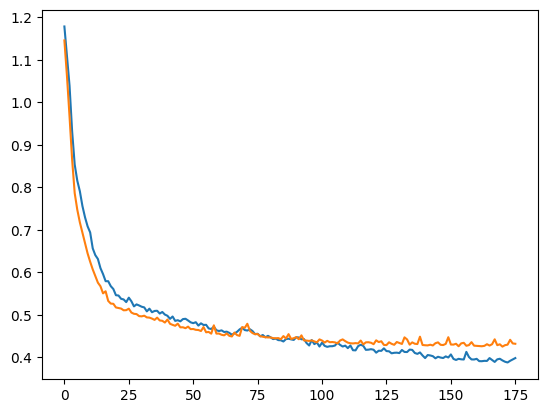

In [107]:
plt.plot(train_losses)
plt.plot(test_losses)
# plt.ylim([0,1])

Array([[1.18481426e+01, 9.59868908e+00, 1.95274448e+01, ...,
        4.97318115e+03, 4.97318115e+03, 4.97318115e+03],
       [1.03976181e+02, 1.06196594e+02, 1.02010468e+02, ...,
        8.37443984e+04, 8.37443984e+04, 8.37443984e+04],
       [2.02085185e+00, 1.18104231e+00, 1.61575854e+00, ...,
        2.65588989e+02, 2.65588989e+02, 2.65588989e+02],
       ...,
       [5.64944496e+01, 4.54925652e+01, 4.86977005e+01, ...,
        8.12331934e+03, 8.12331934e+03, 8.12331934e+03],
       [3.09843242e-01, 4.12309974e-01, 3.84333432e-01, ...,
        2.55019821e+02, 2.55019821e+02, 2.55019821e+02],
       [1.73855270e+02, 1.92855606e+02, 1.78730179e+02, ...,
        5.06857406e+05, 5.06857406e+05, 5.06857406e+05]], dtype=float32)

In [48]:
d_mask.shape

(255, 200)

In [121]:
x_d.shape

(256, 200, 18)

In [124]:
y_hat.shape

(256, 200)

In [59]:
n.shape

(255, 32)

(array([86., 45., 30., 13., 12., 16., 10., 15.,  8., 21.]),
 array([0.02444533, 0.08189729, 0.13934925, 0.1968012 , 0.25425318,
        0.31170511, 0.36915708, 0.42660904, 0.484061  , 0.54151297,
        0.59896493]),
 <BarContainer object of 10 artists>)

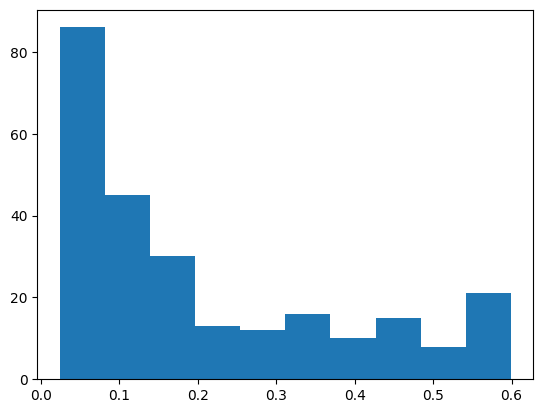

In [127]:
plt.hist(n)

Calculating training statistics for encoding and normalization...


Caching test: 100%|██████████| 278/278 [01:06<00:00,  4.16it/s]


Wrote 278 new Zarr files.
✅ Saved 263244 indices to /scratch4/workspace/tlanghorst_umass_edu-zbs_vD/_cache4/8fba0b5cd6b6f05c/test/_indices/sequence=90
All caches created and indexed.
Calculating training statistics for encoding and normalization...
Loading basin graphs...Done!
Loading optimized indices for test...Done!


Caching basins in memory: 100%|██████████| 278/278 [03:27<00:00,  1.34it/s]


In [77]:
y_hat.shape

(256, 32, 200)

In [97]:
subbasin_list = []
y_list = []
y_pred_list = []
y_pred_std_list = []
A0_list = []
n_list = []
h_list = []
w_list = []
s_list = []

key = jax.random.PRNGKey(0)
keys = jax.random.split(key)

for batch in tqdm(train_loader):
    basin, subbasin, x_d, d_mask, x_s, hws, y = batch
    d_mask = d_mask[..., 0] #bandaid
    y = y[...,0]

    # y_hat, A0, n = jax.vmap(model)(x_d, d_mask, x_s, hws)
    batch_keys = jax.random.split(keys[0], x_d.shape[0])
    key = keys[1]
    y_hat, A0, n = jax.vmap(model)(x_d, d_mask, x_s, hws, batch_keys)
    y_hat_mean = jnp.mean(y_hat, axis=1)
    y_hat_std = jnp.std(y_hat, axis=1)

    A0 = jnp.mean(A0, axis=1)
    n = jnp.mean(n, axis=1)

    y = test_dataset.denormalize(y, 'discharge')

    for i in range(y.shape[0]):
        mask_ids = np.where(d_mask[i,:])[0]
        n_obs = len(mask_ids)

        subbasin_list.append(np.tile(subbasin[i], n_obs))
        y_list.append(y[i, mask_ids])
        y_pred_list.append(y_hat_mean[i, mask_ids])
        y_pred_std_list.append(y_hat_std[i, mask_ids])
        A0_list.append(np.tile(A0[i], n_obs))
        n_list.append(np.tile(n[i], n_obs))
        h_list.append(hws[i,mask_ids,0])
        w_list.append(hws[i,mask_ids,1])
        s_list.append(hws[i,mask_ids,2])

pred_data = {
    'subbasin': np.concatenate(subbasin_list),
    'Q_obs': np.concatenate(y_list),
    'Q_hat': np.concatenate(y_pred_list),
    'Q_hat_std': np.concatenate(y_pred_list),
    'A0': np.concatenate(A0_list),
    'n': np.concatenate(n_list),
    'h': np.concatenate(h_list),
    'w': np.concatenate(w_list),
    's': np.concatenate(s_list),
}

results = pd.DataFrame(pred_data)

100%|██████████| 7/7 [01:27<00:00, 12.48s/it]


array([[<Axes: title={'center': 'n'}>]], dtype=object)

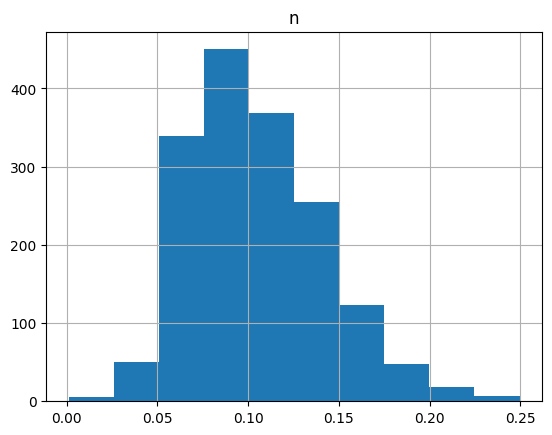

In [98]:
reach_avg = results.groupby('subbasin').mean()
reach_avg.hist('n')

In [99]:
results.to_parquet('./reach_parameter_results.parquet')

In [100]:
results

,subbasin,Q_obs,Q_hat,Q_hat_std,A0,n,h,w,s
0,BRANA-46790000,67.882904,38.989731,38.989731,42.261356,0.118243,-0.0805,25.591303,0.000357
1,BRANA-46790000,80.630394,60.901352,60.901352,42.261356,0.118243,0.3502,19.780722,0.000323
2,BRANA-46790000,79.365707,41.746761,41.746761,42.261356,0.118243,0.0540,27.420652,0.000343
3,BRANA-46790000,134.203003,85.667313,85.667313,42.261356,0.118243,0.9565,38.863468,0.000332
4,BRANA-46790000,126.002022,74.147758,74.147758,42.261356,0.118243,0.7645,46.764034,0.000338
...,...,...,...,...,...,...,...,...,...
70040,ECCC-08NA002,120.100677,91.834724,91.834724,194.794495,0.151916,0.0762,167.357117,0.000136
70041,ECCC-08NA002,122.531227,310.005402,310.005402,194.794495,0.151916,1.1045,108.895370,0.000234
70042,ECCC-08NA002,101.189621,165.425949,165.425949,194.794495,0.151916,0.4845,117.220261,0.000150
70043,ECCC-08NA002,91.641663,136.207840,136.207840,194.794495,0.151916,0.3349,108.945801,0.000120


In [ ]:
def get_corr(grp):
    return grp[['h','w']].corr().iloc[0,1]

results.groupby('subbasin').apply(get_corr, include_groups=False)

In [101]:
from evaluate import metrics

def get_nse(grp):
    y = grp['Q_obs']
    y_pred = grp['Q_hat']

    kge_results = metrics.calc_kge(y, y_pred)
    if isinstance(kge_results, tuple):
        kge, corr, alpha, beta = kge_results
    else:
        kge = corr = alpha = beta = np.nan
    out = {
        'kge': kge,
        'corr': corr,
        'alpha': alpha,
        'beta': beta
    }
    return pd.Series(out)
    
kge = results.groupby('subbasin').apply(get_nse, include_groups=False).dropna()
kge

,kge,corr,alpha,beta
subbasin,,,,
ABOM-122989010,-5.137937,0.912099,5.415518,5.262598
ABOM-123639010,-16.895577,0.238570,8.785708,17.095175
ABOM-123774010,-1.265329,0.879125,1.539092,3.196927
ABOM-128547010,-0.451774,0.947371,1.527402,2.351564
ABOM-132966010,-0.276832,0.896728,1.679687,2.075947
...,...,...,...,...
USGS-15565447,-0.767288,0.538914,2.281728,2.126001
USGS-15580095,0.672530,0.871492,1.264093,1.144836
USGS-15744500,0.485072,0.789558,0.560864,0.832594


(-1.0, 1.0)

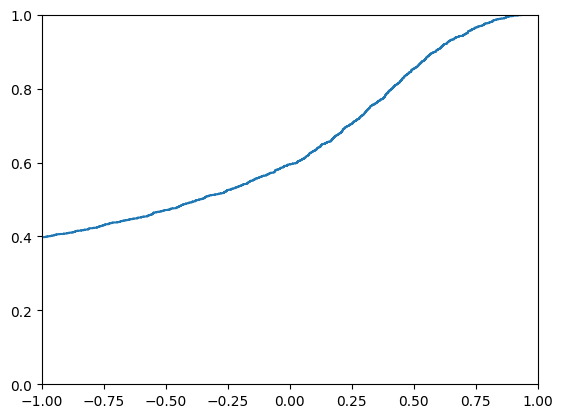

In [102]:
plt.ecdf(kge['kge'])
plt.xlim([-1,1])

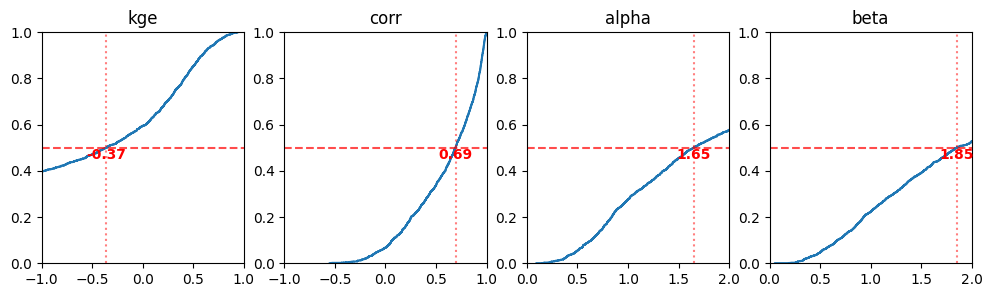

In [103]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
lims = [(-1, 1), (-1, 1), (0, 2), (0, 2)]

for c, ax, lim in zip(kge.columns, axes, lims):
    y = kge[c].dropna()
    median_val = np.median(y)
    
    # Plot ECDF
    ax.ecdf(y)
    
    # Horizontal line at median (0.5 for ECDF)
    ax.axhline(0.5, color='red', linestyle='--', alpha=0.7)
    
    # Vertical indicator or text label for the metric value
    ax.text(median_val, 0.45, f'{median_val:.2f}', 
            color='red', fontweight='bold', ha='center')
    
    # Optional: vertical line to intersection
    ax.axvline(median_val, color='red', linestyle=':', alpha=0.5)
    
    ax.set_xlim(lim)
    ax.set_title(c)

In [69]:
kge.sort_values('kge')

,kge,corr,alpha,beta
subbasin,,,,
USGS-04152049,-139.623805,0.300772,129.895706,57.217991
EAUF-V7144010,-98.796989,0.085246,58.334133,82.678635
USGS-01199050,-28.451630,0.668402,24.796053,18.350401
USGS-11342000,-14.223304,0.236929,11.617500,11.882803
USGS-14335072,-14.198416,0.119397,13.593561,9.462778
...,...,...,...,...
ABOM-8300010,0.965391,0.983847,0.970674,1.008768
USGS-15129120,0.969381,0.988855,0.987052,1.025410
BRANA-25700000,0.977308,0.991359,0.984155,1.013755


<Axes: xlabel='Q_obs', ylabel='Q_hat'>

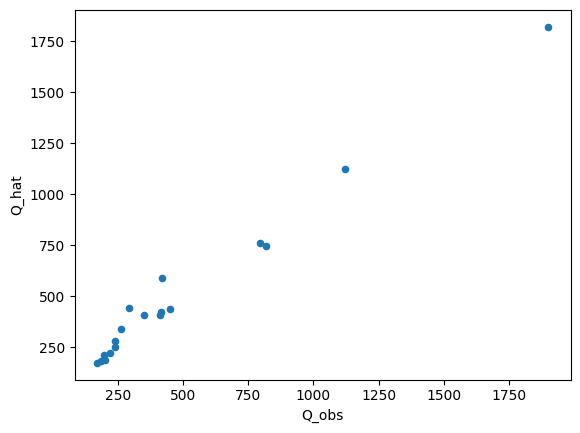

In [89]:
basin_results = results[results['subbasin'] == 'BRANA-25700000']

basin_results.plot.scatter('Q_obs','Q_hat')

In [90]:
basin_results

,subbasin,Q_obs,Q_hat,A0,n,h,w,s
39181,BRANA-25700000,291.917114,440.858795,944.37085,0.042473,0.04305,450.710754,0.000137
39182,BRANA-25700000,259.418060,338.041718,944.37085,0.042473,-0.18565,447.623199,0.000116
39183,BRANA-25700000,239.566025,252.596542,944.37085,0.042473,-0.33555,508.845245,0.000110
39184,BRANA-25700000,217.680008,222.872818,944.37085,0.042473,-0.52175,475.211548,0.000111
39185,BRANA-25700000,196.666077,213.191757,944.37085,0.042473,-0.59485,474.735748,0.000120
39186,BRANA-25700000,419.535034,587.970337,944.37085,0.042473,0.52455,466.435577,0.000127
39187,BRANA-25700000,415.875000,419.906616,944.37085,0.042473,0.15845,522.697815,0.000122
39188,BRANA-25700000,817.181091,744.502869,944.37085,0.042473,0.97815,538.945801,0.000121
39189,BRANA-25700000,1900.479248,1822.001709,944.37085,0.042473,2.94435,553.728333,0.000116
39190,BRANA-25700000,796.685242,760.664917,944.37085,0.042473,1.03915,481.374023,0.000116


<Axes: xlabel='h', ylabel='w'>

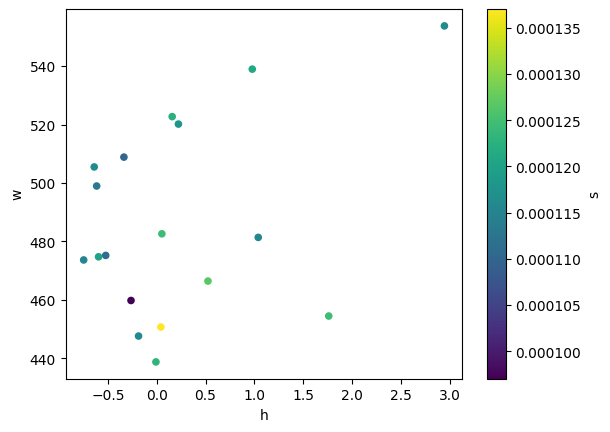

In [91]:
basin_results.plot.scatter('h','w', c='s')

In [30]:
basin_results

,subbasin,Q_obs,Q_hat,A0,n,h,w,s
472,USGS-06191500,98.259468,156.995468,86.676651,0.10395,1.2308,81.089203,0.002523
473,USGS-06191500,55.501030,53.021244,86.676651,0.10395,0.1287,78.798744,0.002463
474,USGS-06191500,49.837666,56.193810,86.676651,0.10395,0.1746,78.241646,0.002433
475,USGS-06191500,46.722805,104.759300,86.676651,0.10395,0.7298,81.326859,0.002548
476,USGS-06191500,46.156464,59.004116,86.676651,0.10395,0.2278,86.099831,0.002514
477,USGS-06191500,35.112892,33.660408,86.676651,0.10395,-0.1541,79.924232,0.002438
478,USGS-06191500,33.413883,39.619022,86.676651,0.10395,-0.0722,78.924950,0.002499
479,USGS-06191500,28.316849,31.816534,86.676651,0.10395,-0.1817,80.020782,0.002414
480,USGS-06191500,26.674473,86.810829,86.676651,0.10395,0.5540,85.573486,0.002489
481,USGS-06191500,27.467348,49.320309,86.676651,0.10395,0.0680,77.818474,0.002487


In [31]:
y_obs

NameError: name 'y_obs' is not defined